In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

raw = pd.read_csv(
    "data/galaxies/sdss_galaxies_raw.csv",
    dtype={"specObjID": "string"},
)

raw.info()

FileNotFoundError: [Errno 2] No such file or directory: 'data/galaxies/sdss_galaxies_raw.csv'

In [ ]:
df_na = raw.replace([np.inf, -np.inf], np.nan).dropna().copy()

pd.DataFrame({
    "raw": [len(raw)],
    "raw.na": [len(raw) - len(df_na)],
    "raw.left": [len(df_na)],
})

,raw,raw.na,raw.left
0,521232,0,521232


In [ ]:
df_unique = (
    df_na.drop_duplicates(subset="specObjID")
    .reset_index(drop=True)
)

pd.DataFrame({
    "drop_duplicates": [len(df_na) - len(df_unique)],
    "left": [len(df_unique)],
})

,drop_duplicates,left
0,0,521232


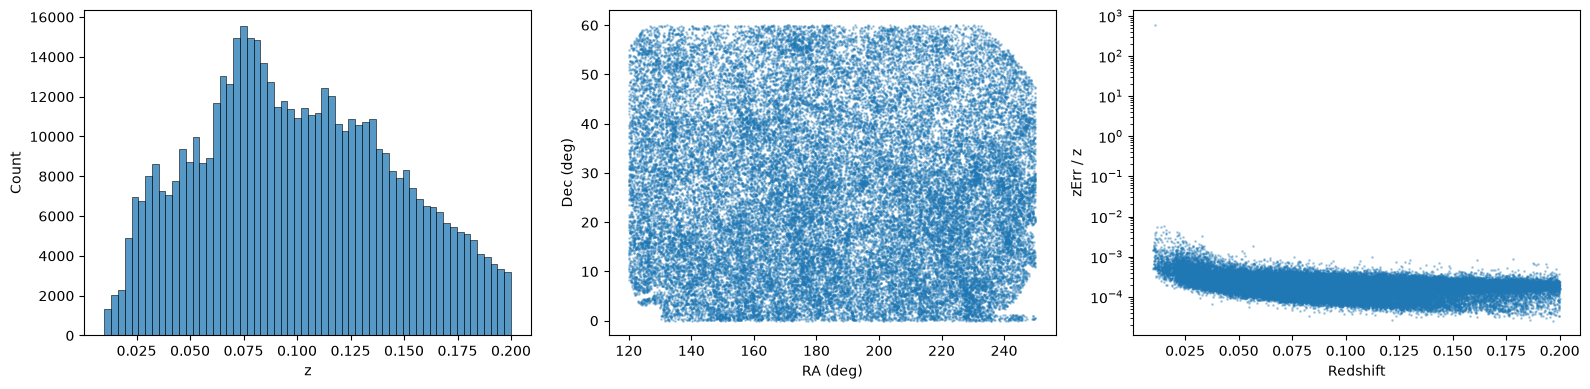

In [ ]:
plot_sample = df_unique.sample(
    n=min(50000, len(df_unique)),
    random_state=42,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    data=df_unique,
    x="z",
    bins=60,
    ax=axes[0],
)

axes[1].scatter(
    plot_sample["ra"],
    plot_sample["dec"],
    s=1,
    alpha=0.3,
)
axes[1].set(xlabel="RA (deg)", ylabel="Dec (deg)")

error_sample = plot_sample.loc[
    (plot_sample["z"] > 0) & (plot_sample["zErr"] > 0)
]

axes[2].scatter(
    error_sample["z"],
    error_sample["zErr"] / error_sample["z"],
    s=1,
    alpha=0.3,
)
axes[2].set(
    xlabel="Redshift",
    ylabel="zErr / z",
    yscale="log",
)

plt.tight_layout()
plt.show()

In [ ]:
Z_MIN = 0.03
Z_MAX = 0.20

RA_MIN = 120
RA_MAX = 250

DEC_MIN = 0
DEC_MAX = 60

MAX_REL_ZERR = None

SAMPLE_SIZE = 10000
SEED = 42

In [ ]:
mask = (
    df_unique["class"].str.strip().eq("GALAXY")
    & df_unique["zWarning"].eq(0)
    & df_unique["z"].between(Z_MIN, Z_MAX, inclusive="neither")
    & df_unique["ra"].between(RA_MIN, RA_MAX, inclusive="left")
    & df_unique["dec"].between(DEC_MIN, DEC_MAX)
    & df_unique["zErr"].gt(0)
    & df_unique["zErr"].lt(df_unique["z"])
)

if MAX_REL_ZERR is not None:
    mask &= (
        df_unique["zErr"] / df_unique["z"]
    ).le(MAX_REL_ZERR)

df_clean = df_unique.loc[mask].copy().reset_index(drop=True)

if df_clean.empty:
    raise ValueError("선택 조건을 만족하는 데이터 없음")

summary = pd.DataFrame({
    "단계": ["원본", "NA 제거", "중복 제거", "컷 적용"],
    "행 수": [
        len(raw),
        len(df_na),
        len(df_unique),
        len(df_clean),
    ],
})

summary

,단계,행 수
0,원본,521232
1,NA 제거,521232
2,중복 제거,521232
3,컷 적용,494502


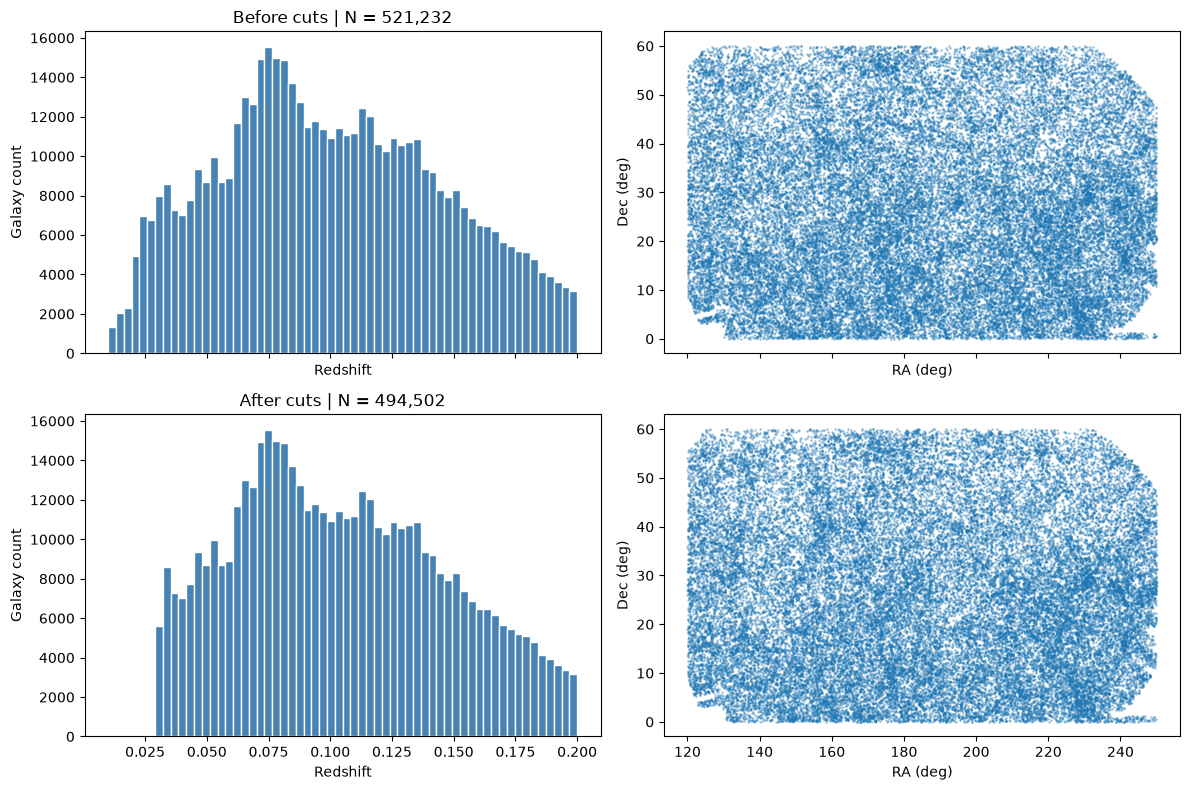

In [ ]:
bins = np.linspace(
    df_unique["z"].min(),
    df_unique["z"].max(),
    61,
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex="col",
    sharey="col",
)

for row, (title, frame) in enumerate([
    ("Before cuts", df_unique),
    ("After cuts", df_clean),
]):
    axes[row, 0].hist(
        frame["z"],
        bins=bins,
        color="steelblue",
        edgecolor="white",
    )
    axes[row, 0].set(
        title=f"{title} | N = {len(frame):,}",
        xlabel="Redshift",
        ylabel="Galaxy count",
    )

    sample = frame.sample(
        n=min(50000, len(frame)),
        random_state=SEED,
    )

    axes[row, 1].scatter(
        sample["ra"],
        sample["dec"],
        s=1,
        alpha=0.3,
    )
    axes[row, 1].set(
        xlabel="RA (deg)",
        ylabel="Dec (deg)",
    )

plt.tight_layout()
plt.show()

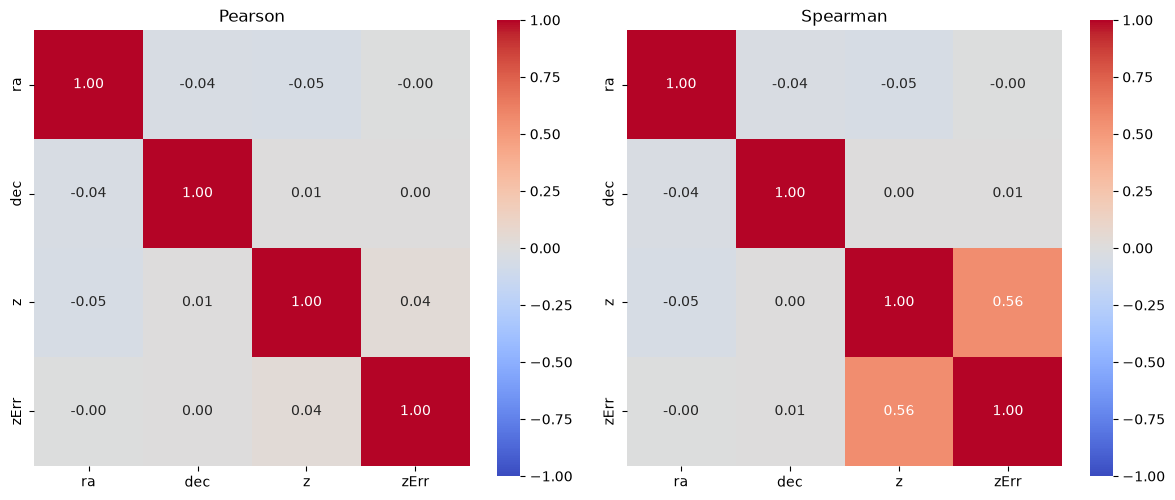

,고유값 수,표준편차
ra,485052,36.676397
dec,492822,16.400057
z,457268,0.042442
zErr,468328,0.000174
zWarning,1,0.000000


In [ ]:
numeric = df_clean.select_dtypes(include="number")

column_summary = pd.DataFrame({
    "고유값 수": numeric.nunique(),
    "표준편차": numeric.std(),
})

numeric = numeric.loc[:, numeric.nunique() > 1]

pearson = numeric.corr(method="pearson")
spearman = numeric.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, title, correlation in [
    (axes[0], "Pearson", pearson),
    (axes[1], "Spearman", spearman),
]:
    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

column_summary

In [ ]:
DROP_COLUMNS = []

df_analysis = df_clean.drop(columns=DROP_COLUMNS).copy()

df_analysis.to_csv(
    "data/galaxies/galaxies_processed.csv.gz",
    index=False,
    compression="gzip",
)

summary.to_csv(
    "data/galaxies/preprocessing_summary.csv",
    index=False,
)

pearson.to_csv("data/galaxies/correlation_pearson.csv")
spearman.to_csv("data/galaxies/correlation_spearman.csv")

pd.DataFrame({
    "행 수": [len(df_analysis)],
    "열 수": [df_analysis.shape[1]],
})

,specObjID,ra,dec,z,zErr,zWarning,class
0,495401488193972224,124.86550,48.453868,0.180736,0.000056,0,GALAXY
1,495402862583506944,125.01663,48.847020,0.154864,0.000042,0,GALAXY
2,495406435996297216,124.87658,49.039169,0.140260,0.000022,0,GALAXY
3,495561192257906688,125.06450,49.859703,0.094595,0.000026,0,GALAXY
4,495561467135813632,125.05615,49.844886,0.138068,0.000026,0,GALAXY


In [ ]:
settings = pd.Series({
    "source": "sdss_galaxies_raw.csv",
    "output": "galaxies_processed.csv.gz",
    "z_min": Z_MIN,
    "z_max": Z_MAX,
    "ra_min": RA_MIN,
    "ra_max": RA_MAX,
    "dec_min": DEC_MIN,
    "dec_max": DEC_MAX,
    "max_relative_z_error": MAX_REL_ZERR,
    "class": "GALAXY",
    "zWarning": 0,
    "redshift_error_rule": "0 < zErr < z",
    "duplicate_key": "specObjID",
    "drop_columns": DROP_COLUMNS,
    "selected_columns": df_analysis.columns.tolist(),
    "rows": len(df_analysis),
})

settings.to_json(
    "data/galaxies/selection_config.json",
    force_ascii=False,
    indent=2,
)

,자료,행 수,열 수
0,전체 분석용,521217,7
1,Git용,10000,7
